# 04 — Results, coverage and reproducibility

Read executed Development manifests, verify checkpoint/journal hashes, and inspect metrics/costs. CPU analysis only; no hyperparameter selection or training.

## Environment and artifact setup

Use Python 3.12 as documented in the repository. Install the pinned PyTorch requirement (requirements-model.txt from the CPU index, or requirements-cuda.txt from the cu126 index), plus requirements-dev.txt. Notebook presentation dependencies used for recorded validation: nbformat 5.10.4, nbclient 0.10.2, ipykernel 6.29.5, pandas 3.0.1, matplotlib 3.10.8.

Open from the repository or set HUNG_REPO_ROOT. Download/extract identified inputs and run artifacts; set HUNG_INPUT_BASE and HUNG_RUN_ROOT if locations differ. Missing files fail explicitly. Large inputs/checkpoints stay outside Git; only load trusted project checkpoints.

Default cells inspect existing evidence and run small CPU examples. They do not launch matrix training. Recorded matrix code SHA: a34a49e5f04920ef30456fe6c0ea56eb2f1d659a, diagnostic config v1 and selection v2. Clean CPU reproduction was validated in a new isolated repo-local Python 3.13.7 environment with torch 2.8.0+cpu, pip check, the full unit suite and a fresh kernel per notebook. README's reference Python 3.12 environment was not executed in this local check. The global CUDA environment has an unrelated ultralytics/numpy conflict; it was not inherited by the isolated environment.


In [1]:
import hashlib
import json
import os
import sys
from pathlib import Path

import pandas as pd

candidates = (
    [Path(os.environ["HUNG_REPO_ROOT"])]
    if os.environ.get("HUNG_REPO_ROOT")
    else [Path.cwd(), *Path.cwd().parents]
)
REPO = next(
    (
        path.resolve()
        for path in candidates
        if (path / "experiments/hung_sprint2/model.py").is_file()
    ),
    None,
)
if REPO is None:
    raise FileNotFoundError("Set HUNG_REPO_ROOT to the checked-out repository.")
sys.path.insert(0, str(REPO))
RUN_ROOT = Path(
    os.environ.get("HUNG_RUN_ROOT", str(REPO / "runs/hung-39-representative-local-20261025T2103"))
).resolve()
INPUT_BASE = Path(
    os.environ.get("HUNG_INPUT_BASE", str(REPO / "data/inputs/issue18-input-handoff-v1-20261019"))
).resolve()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


identity = read_json(RUN_ROOT / "matrix_identity.json")
config = read_json(REPO / "experiments/hung_sprint2/development_config_v1.json")
assert identity["phase"] == "representative"
assert identity["config_sha256"] == sha256(
    REPO / "experiments/hung_sprint2/development_config_v1.json"
)
assert identity["selection_sha256"] == sha256(
    REPO / "docs/reports/hung-development-selection-20261025-v2.json"
)
print(
    {
        "run_id": RUN_ROOT.name,
        "execution_code_sha": identity["code"]["commit"],
        "device": identity["device"],
    }
)

{'run_id': 'hung-39-representative-local-20261025T2103', 'execution_code_sha': 'a34a49e5f04920ef30456fe6c0ea56eb2f1d659a', 'device': 'cuda'}


## Evaluation

MAE/RMSE use original kWh and only forecasts with all 24 valid labels arrived. Requested origins, issued forecasts and scored days have different denominators. Null means no scored complete days and must remain null. Source-checkpoint-only is a separate stratum; candidate/audit costs are separate from whole-session wall time.

In [2]:
audit = read_json(RUN_ROOT / "audit_summary.json")
assert audit["run_id"] == RUN_ROOT.name
assert audit["completed_stages"] == audit["expected_stages"] == 216
assert not audit["missing"] and len(audit["rows"]) == 69
checked = 0
for path in RUN_ROOT.rglob("run_manifest.json"):
    manifest = read_json(path)
    stage = path.parent.name
    checkpoint_name = (
        "runner_checkpoint.pt" if stage.startswith("replay") else f"{stage}_checkpoint.pt"
    )
    expected = manifest.get("checkpoint_sha256", manifest.get("final_runner_checkpoint_sha256"))
    assert manifest["status"] == "completed"
    assert sha256(path.parent / checkpoint_name) == expected, path
    checked += 1
    journal = manifest.get("event_journal")
    if journal:
        assert sha256(path.parent / journal["file"]) == journal["sha256"], path
        checked += 1
assert checked == audit["hashes_checked"] == 354
print(
    {
        "completed_stages": 216,
        "checkpoint_journal_hashes_verified": checked,
        "replay_rows": len(audit["rows"]),
        "matrix_identity_sha256": sha256(RUN_ROOT / "matrix_identity.json"),
    }
)
rows = pd.DataFrame(audit["rows"])
columns = [
    "budget",
    "seed",
    "entity_id",
    "initialization",
    "requested_origins",
    "issued_forecasts",
    "scored_complete_days",
    "mae_kwh",
    "rmse_kwh",
    "switches",
    "keeps",
]
rows[columns]

{'completed_stages': 216, 'checkpoint_journal_hashes_verified': 354, 'replay_rows': 69, 'matrix_identity_sha256': 'adf6832efce4afed0652b78967b1dc5ca8aba2e3763e1cb333a99f93191d1079'}


,budget,seed,entity_id,initialization,requested_origins,issued_forecasts,scored_complete_days,mae_kwh,rmse_kwh,switches,keeps
0,7,7,1405,target_initial_adaptation,90,90,89,5.913999,8.148551,3,3
1,7,7,2264,target_initial_adaptation,90,90,90,3.661227,5.911514,1,5
2,7,7,2452,target_initial_adaptation,90,59,52,6.159588,8.612132,1,5
3,7,7,1050,source_checkpoint_only,90,90,0,NaN,NaN,0,6
4,7,7,1200,source_checkpoint_only,90,59,0,NaN,NaN,0,6
...,...,...,...,...,...,...,...,...,...,...,...
64,28,19,1165,target_initial_adaptation,90,59,52,10.320419,13.526531,1,5
65,28,19,2633,target_initial_adaptation,90,59,52,2.139804,3.657856,0,6
66,28,19,1188,source_checkpoint_only,90,59,0,NaN,NaN,0,6
67,28,19,1408,source_checkpoint_only,90,58,0,NaN,NaN,0,6


In [3]:
display(pd.DataFrame(audit["source_only_labels"]))
display(
    rows[
        [
            "budget",
            "seed",
            "entity_id",
            "stage_duration_seconds",
            "candidate_update_steps",
            "audit_update_steps",
            "peak_cuda_allocated_bytes",
        ]
    ]
)
assert rows.loc[rows["scored_complete_days"] == 0, "mae_kwh"].isna().all()
assert rows.loc[rows["scored_complete_days"] == 0, "rmse_kwh"].isna().all()
print("Zero-score metrics remain null; input coverage records explain missing full horizons.")

,budget,complete_24h,entity_id,missing_hours,records
0,7,0,1050,708,90
1,7,0,1200,1062,90
2,7,0,2447,1270,90
3,14,0,1025,1540,90
4,14,0,2613,1057,90
5,14,0,2644,1061,90
6,28,0,1188,1061,90
7,28,0,1251,1168,90
8,28,0,1408,1179,90


,budget,seed,entity_id,stage_duration_seconds,candidate_update_steps,audit_update_steps,peak_cuda_allocated_bytes
0,7,7,1405,"{'replay_42': 9.867563999956474, 'replay_90': ...","[89, 89, 89]",42,85135360
1,7,7,2264,"{'replay_42': 11.339569199946709, 'replay_90':...","[90, 90, 90]",14,85135360
2,7,7,2452,"{'replay_42': 11.113228000001982, 'replay_90':...","[52, 52, 52]",0,85135360
3,7,7,1050,"{'replay_42': 7.240040400065482, 'replay_90': ...","[0, 0, 0]",0,85135360
4,7,7,1200,"{'replay_42': 7.167433799942955, 'replay_90': ...","[0, 0, 0]",0,85135360
...,...,...,...,...,...,...,...
64,28,19,1165,"{'replay_42': 10.683980999980122, 'replay_90':...","[52, 52, 52]",10,85135360
65,28,19,2633,"{'replay_42': 13.707840400049463, 'replay_90':...","[52, 52, 52]",0,85135360
66,28,19,1188,"{'replay_42': 9.334382400033064, 'replay_90': ...","[0, 0, 0]",0,85135360
67,28,19,1408,"{'replay_42': 9.834260800038464, 'replay_90': ...","[0, 0, 0]",0,85135360


Zero-score metrics remain null; input coverage records explain missing full horizons.


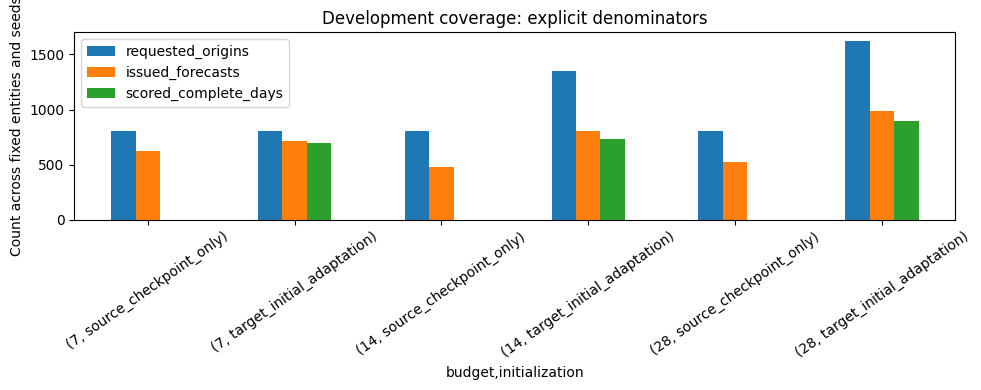

Coverage differs across entities/budgets; this is not an effectiveness comparison.


In [4]:
import matplotlib.pyplot as plt

coverage = rows.groupby(["budget", "initialization"])[
    ["requested_origins", "issued_forecasts", "scored_complete_days"]
].sum()
ax = coverage.plot.bar(figsize=(10, 4), rot=35)
ax.set_ylabel("Count across fixed entities and seeds")
ax.set_title("Development coverage: explicit denominators")
plt.tight_layout()
plt.show()
print("Coverage differs across entities/budgets; this is not an effectiveness comparison.")

## Reproduction and limits

Run artifacts include matrix identity, manifests/checkpoints/journals and audit summary. Phase D/E reports index the durable archive and recovery instructions. Training reproduction uses notebook 03 with a new root; resume requires original identity and compatible environment/device. CPU model inference differs from resuming CUDA runner RNG/state.

Results establish execution and bounded correctness evidence, not baseline superiority, full-cohort coverage, an approved configuration, co-lead agreement or Final/test results. Freeze completed evidence at handoff; rerun only for a concrete failure or reviewer verification.